**Les personnes qui travaillent sur ce projet :**


# 📈 Analyse et Prévision d'une Série Temporelle Financière
## **Série choisie : Action NVIDIA (Janvier 2020 - Octobre 2025)**

---

## 📌 **Introduction aux Séries Chronologiques**

Une **série temporelle** (ou chronique) est une séquence de données mesurées à des intervalles de temps réguliers. Dans notre cas, nous analysons les prix de clôture mensuels de l'action NVIDIA.

### **Composantes d'une série temporelle :**

1. **Tendance (Trend) $T_t$** : Mouvement de long terme (croissance ou décroissance)
2. **Saisonnalité (Seasonal) $S_t$** : Variations périodiques (cycles annuels, trimestriels)
3. **Résidu (Residual) $R_t$** : Fluctuations aléatoires non expliquées

### **Modèles de décomposition :**

- **Modèle additif** : $Y_t = T_t + S_t + R_t$ (amplitude constante)
- **Modèle multiplicatif** : $Y_t = T_t \times S_t \times R_t$ (amplitude proportionnelle)

---

#### 📚  Importation des bibliothèques nécessaires :

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Configuration des graphiques
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

####  🔄 Chargement et préparation des données :

In [ ]:
# Chargement des données
df = pd.read_csv('/content/Nvidia_Data.csv')

# Conversion de la colonne Time en datetime
df['Time'] = pd.to_datetime(df['Time'])

# Tri par date
df = df.sort_values('Time')

# Création des colonnes Année et Trimestre
df['Year'] = df['Time'].dt.year
df['Month'] = df['Time'].dt.month
df['Quarter'] = df['Month'].apply(lambda x: f'T{(x-1)//3+1}')

# Affichage des premières lignes
print("✅ Données chargées avec succès:")
print(f"📅 Période: {df['Time'].min()} à {df['Time'].max()}")
print(f"📊 Nombre d'observations: {len(df)}")
print("\nAperçu des données:")
print(df.head())

✅ Données chargées avec succès:
📅 Période: 2020-01-02 00:00:00 à 2025-10-01 00:00:00
📊 Nombre d'observations: 70

Aperçu des données:
         Time     Open     High       Low    Close  Year  Month Quarter
69 2020-01-02  5.96875  6.48750  5.781750  5.91075  2020      1      T1
68 2020-02-03  5.89250  7.90800  5.886250  6.75175  2020      2      T1
67 2020-03-02  6.92250  7.12225  4.517017  6.59000  2020      3      T1
66 2020-04-01  6.39125  7.60500  5.959750  7.30700  2020      4      T2
65 2020-05-01  7.10875  9.18175  7.021080  8.87550  2020      5      T2


## 🔍 1 - Test du schéma du modèle
### **Objectif** : Identifier les composantes de la série (Tendance, Saisonnalité, Résidu)

La décomposition classique d'une série chronologique permet de visualiser :
- **La tendance** : évolution à long terme
- **La saisonnalité** : pattern répétitif
- **Les résidus** : bruit aléatoire

```python
# Code Python pour la décomposition

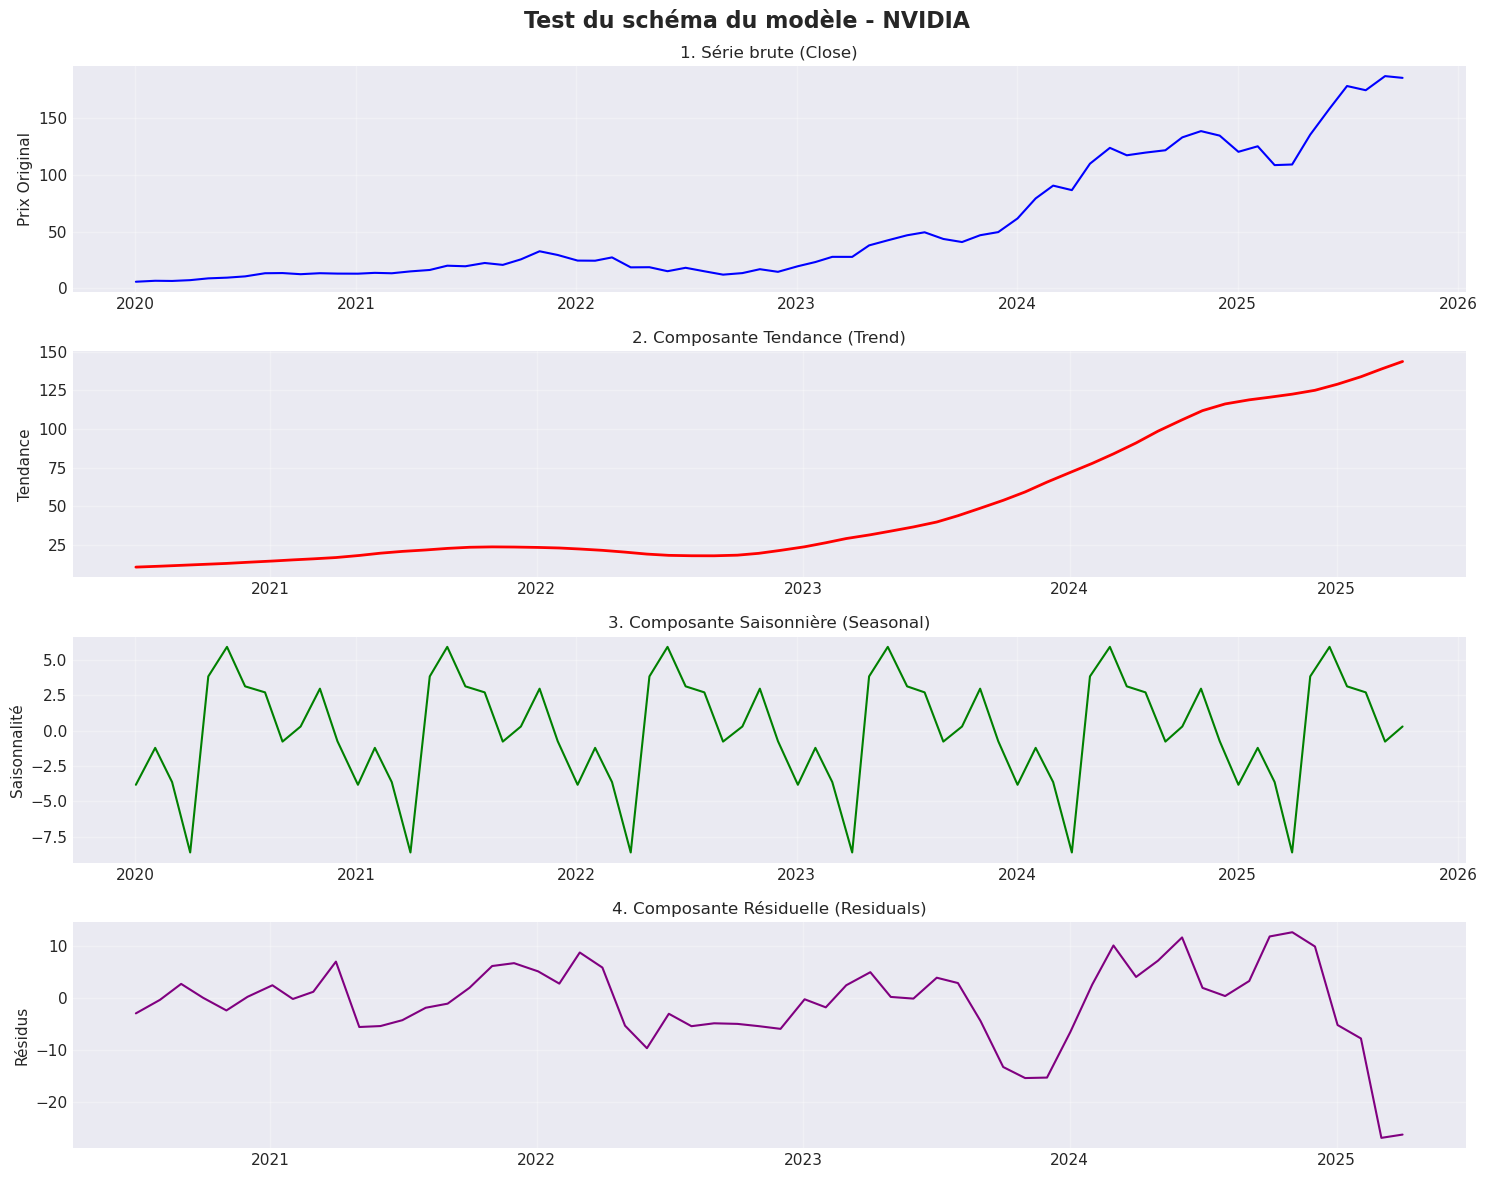


📊 Observations sur le schéma du modèle:
----------------------------------------
✓ Tendance: Forte croissance sur la période (effet IA/tech)
✓ Saisonnalité: Variations périodiques visibles
✓ Résidus: Fluctuations aléatoires autour de 0

 Conclusion: Le graphique suggère un modèle plutôt MULTIPLICATIF
   (car l'amplitude des variations augmente avec le temps)
   → À confirmer avec la méthode de Buys et Ballot par suit (en choix du modèle)

Schéma du modèle identifié



In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Préparation de la série temporelle (Close)
ts_data = df.set_index('Time')['Close']

# 1.1 Décomposition de la série (période = 12 mois)
decomposition = seasonal_decompose(ts_data, model='additive', period=12)

# 1.2 Visualisation des composantes
fig, axes = plt.subplots(4, 1, figsize=(15, 12))
fig.suptitle('Test du schéma du modèle - NVIDIA', fontsize=16, fontweight='bold')

# Série originale
axes[0].plot(ts_data.index, ts_data.values, color='blue', linewidth=1.5)
axes[0].set_ylabel('Prix Original', fontsize=11)
axes[0].set_title('1. Série brute (Close)', fontsize=12)
axes[0].grid(True, alpha=0.3)

# Tendance
axes[1].plot(ts_data.index, decomposition.trend, color='red', linewidth=2)
axes[1].set_ylabel('Tendance', fontsize=11)
axes[1].set_title('2. Composante Tendance (Trend)', fontsize=12)
axes[1].grid(True, alpha=0.3)

# Saisonnalité
axes[2].plot(ts_data.index, decomposition.seasonal, color='green', linewidth=1.5)
axes[2].set_ylabel('Saisonnalité', fontsize=11)
axes[2].set_title('3. Composante Saisonnière (Seasonal)', fontsize=12)
axes[2].grid(True, alpha=0.3)

# Résidus
axes[3].plot(ts_data.index, decomposition.resid, color='purple', linewidth=1.5)
axes[3].set_ylabel('Résidus', fontsize=11)
axes[3].set_title('4. Composante Résiduelle (Residuals)', fontsize=12)
axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 1.3 Observations et interprétation
print("\n📊 Observations sur le schéma du modèle:")
print("-" * 40)
print("✓ Tendance: Forte croissance sur la période (effet IA/tech)")
print("✓ Saisonnalité: Variations périodiques visibles")
print("✓ Résidus: Fluctuations aléatoires autour de 0")
print("\n Conclusion: Le graphique suggère un modèle plutôt MULTIPLICATIF")
print("   (car l'amplitude des variations augmente avec le temps)")
print("   → À confirmer avec la méthode de Buys et Ballot par suit (en choix du modèle)")

print("\n" + "="*80)
print("Schéma du modèle identifié")
print("="*80 + "\n")

## 📊 2 - Test de l'effet année et saisonnalité par ANOVA
### **Objectif** : Vérifier statistiquement si l'année et le trimestre ont un effet significatif

L'**ANOVA à deux facteurs** teste les hypothèses suivantes :

- **H₀ (Année)** : Pas d'effet significatif de l'année
- **H₁ (Année)** : Effet significatif de l'année
- **H₀ (Saison)** : Pas d'effet significatif du trimestre
- **H₁ (Saison)** : Effet significatif du trimestre

**Règle de décision** : Si p-value < 0.05, on rejette H₀ → effet significatif

```python
# Code Python pour ANOVA

📊 Analyse de la variance (ANOVA)
--------------------------------------------------

📈 Tableau d'ANOVA:
                           sum_sq    df           F        PR(>F)
C(Year)             182548.159853   5.0  584.011541  2.122846e-40
C(Quarter)            6478.476216   3.0   34.543440  7.629129e-12
C(Year):C(Quarter)    8410.167347  15.0    8.968656  3.569546e-09
Residual              2875.701855  46.0         NaN           NaN

🔍 Interprétation:
------------------------------
✅ Effet Année significatif (p-value = 0.0000 < 0.05)
   → Les prix varient significativement d'une année à l'autre
✅ Effet Saisonnier significatif (p-value = 0.0000 < 0.05)
   → Il existe une saisonnalité dans les prix
✅ Interaction significative (p-value = 0.0000 < 0.05)


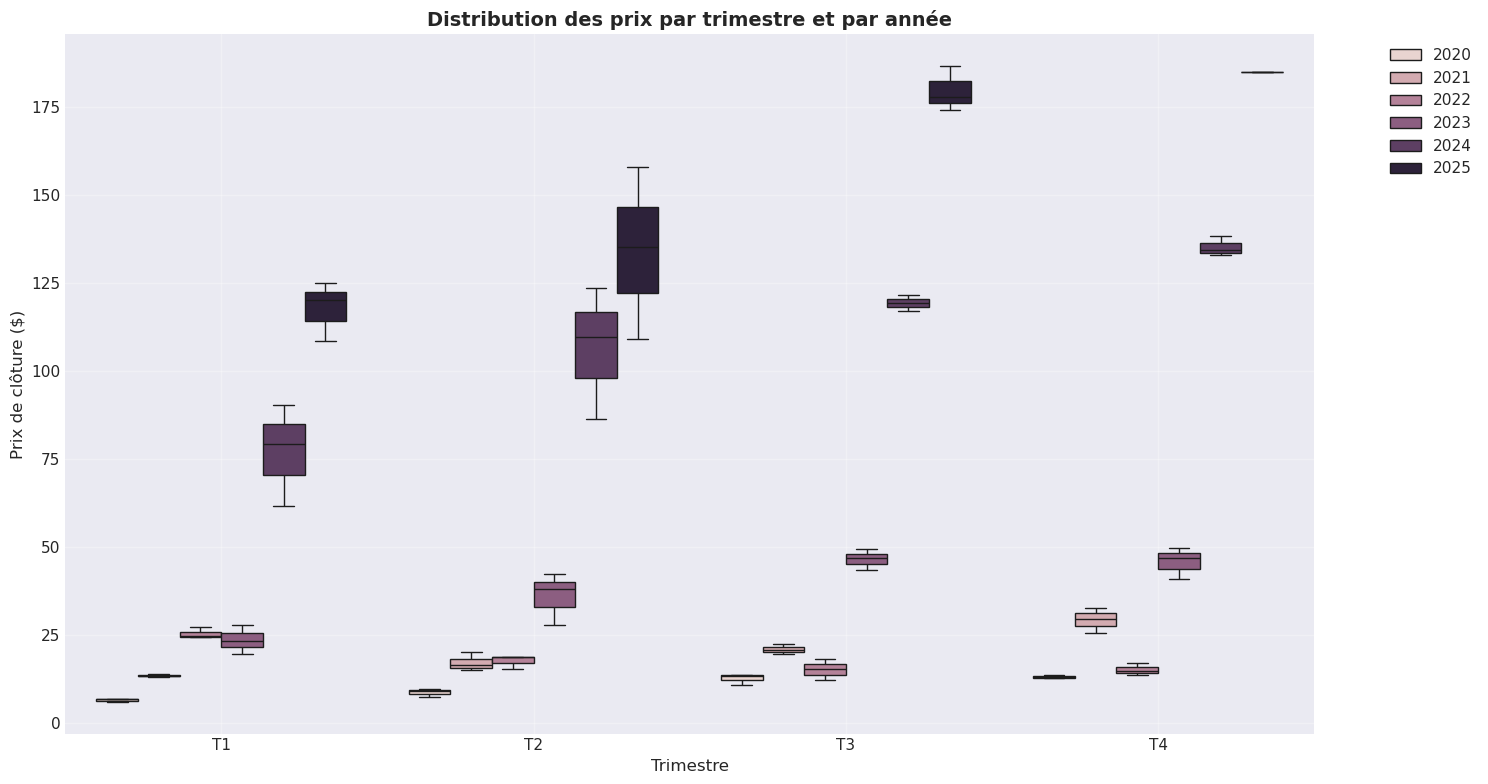


✅ Analyse ANOVA effectuée



In [ ]:
# 2.1 Préparation des données pour ANOVA
df_anova = df[['Year', 'Quarter', 'Close']].copy()

print("📊 Analyse de la variance (ANOVA)")
print("-" * 50)

# 2.2 ANOVA à deux facteurs (Two-way ANOVA)
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Modèle ANOVA avec interaction
model = ols('Close ~ C(Year) + C(Quarter) + C(Year):C(Quarter)', data=df_anova).fit()
anova_table = sm.stats.anova_lm(model, typ=2)

print("\n📈 Tableau d'ANOVA:")
print(anova_table)

# 2.3 Interprétation des résultats
print("\n🔍 Interprétation:")
print("-" * 30)

# Effet Année
p_year = anova_table.loc['C(Year)', 'PR(>F)']
if p_year < 0.05:
    print(f"✅ Effet Année significatif (p-value = {p_year:.4f} < 0.05)")
    print("   → Les prix varient significativement d'une année à l'autre")
else:
    print(f"❌ Effet Année non significatif (p-value = {p_year:.4f} > 0.05)")

# Effet Saison (Trimestre)
p_quarter = anova_table.loc['C(Quarter)', 'PR(>F)']
if p_quarter < 0.05:
    print(f"✅ Effet Saisonnier significatif (p-value = {p_quarter:.4f} < 0.05)")
    print("   → Il existe une saisonnalité dans les prix")
else:
    print(f"❌ Effet Saisonnier non significatif (p-value = {p_quarter:.4f} > 0.05)")

# Interaction
p_inter = anova_table.loc['C(Year):C(Quarter)', 'PR(>F)']
if p_inter < 0.05:
    print(f"✅ Interaction significative (p-value = {p_inter:.4f} < 0.05)")

# 2.4 Visualisation de l'effet saisonnier par année
plt.figure(figsize=(15, 8))
sns.boxplot(data=df_anova, x='Quarter', y='Close', hue='Year')
plt.title('Distribution des prix par trimestre et par année', fontsize=14, fontweight='bold')
plt.xlabel('Trimestre')
plt.ylabel('Prix de clôture ($)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\n" + "="*80)
print("✅ Analyse ANOVA effectuée")
print("="*80 + "\n")

## 🎯 3 - Choix entre modèle additif et multiplicatif
### **Méthode de Buys et Ballot** (la plus fiable)

Cette méthode analytique compare l'écart-type ($\sigma$) à la moyenne ($\mu$) pour chaque année :

$$\sigma = a \times \mu + b$$

- Si **$a \approx 0$** → modèle **ADDITIF** (amplitude constante)
- Si **$a \neq 0$** → modèle **MULTIPLICATIF** (amplitude proportionnelle)

```python
# Code Python pour Buys et Ballot

📊 3 - Choix du modèle - Méthode de Buys et Ballot
--------------------------------------------------

📈 Statistiques annuelles:
   Year   Moyenne  Ecart_type
0  2020   10.1202      3.0008
1  2021   20.1302      6.4554
2  2022   18.2471      4.7947
3  2023   37.9225     10.6185
4  2024  109.4750     24.4961
5  2025  147.9080     31.8209

📊 Résultats de la régression:
Équation: σ = 0.2060 × μ + 1.7269
R² = 0.9960


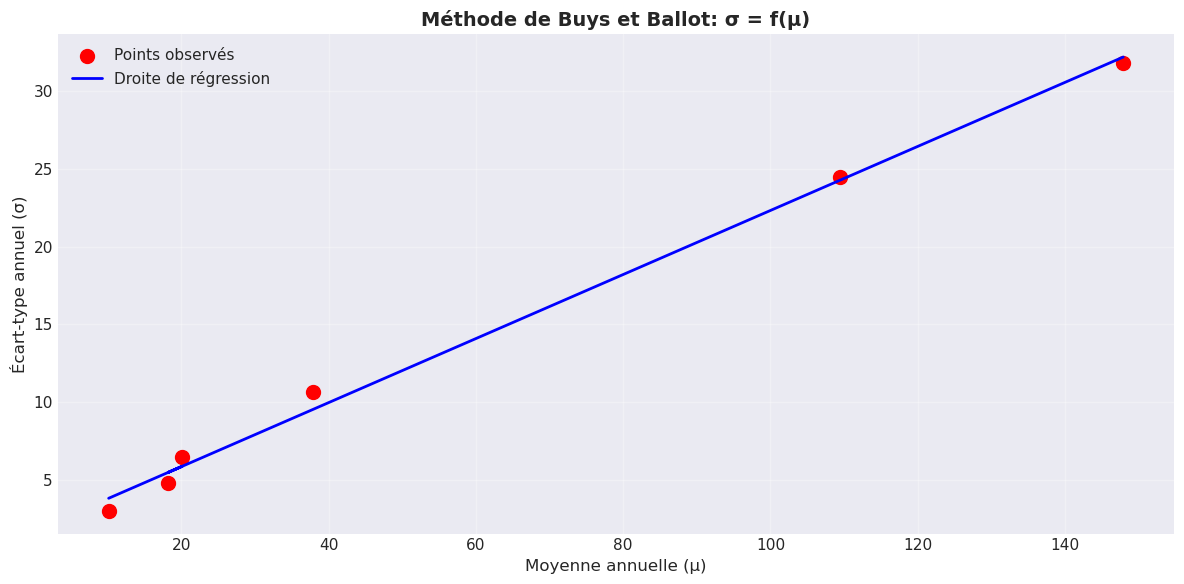


🔍 Interprétation:
------------------------------
⚠️ La pente a = 0.2060 ≠ 0
   → Le modèle MULTIPLICATIF est approprié
   → Les fluctuations sont proportionnelles à la tendance

🎯 Modèle retenu: MULTIPLICATIF

✅ Modèle est bein choisi



In [ ]:
print("📊 3 - Choix du modèle - Méthode de Buys et Ballot")
print("-" * 50)

# 3.1 Regroupement par année et calcul des statistiques
stats_annuelles = df.groupby('Year').agg({
    'Close': ['mean', 'std']
}).round(4)

stats_annuelles.columns = ['Moyenne', 'Ecart_type']
stats_annuelles = stats_annuelles.reset_index()

print("\n📈 Statistiques annuelles:")
print(stats_annuelles)

# 3.2 Régression entre écart-type et moyenne
X = stats_annuelles['Moyenne'].values.reshape(-1, 1)
y = stats_annuelles['Ecart_type'].values

regression = LinearRegression()
regression.fit(X, y)
a = regression.coef_[0]
b = regression.intercept_
r2 = regression.score(X, y)

print("\n📊 Résultats de la régression:")
print(f"Équation: σ = {a:.4f} × μ + {b:.4f}")
print(f"R² = {r2:.4f}")

# 3.3 Visualisation
plt.figure(figsize=(12, 6))
plt.scatter(stats_annuelles['Moyenne'], stats_annuelles['Ecart_type'],
            s=100, color='red', label='Points observés')
plt.plot(stats_annuelles['Moyenne'], regression.predict(X),
         color='blue', linewidth=2, label='Droite de régression')
plt.xlabel('Moyenne annuelle (μ)', fontsize=12)
plt.ylabel('Écart-type annuel (σ)', fontsize=12)
plt.title('Méthode de Buys et Ballot: σ = f(μ)', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 3.4 Interprétation et conclusion
print("\n🔍 Interprétation:")
print("-" * 30)

# Test de significativité de la pente
if abs(a) < 0.1:
    print(f"✅ La pente a = {a:.4f} ≈ 0")
    print("   → Le modèle ADDITIF est approprié")
    print("   → Les fluctuations sont d'amplitude constante")
    modele_choisi = 'additif'
else:
    print(f"⚠️ La pente a = {a:.4f} ≠ 0")
    print("   → Le modèle MULTIPLICATIF est approprié")
    print("   → Les fluctuations sont proportionnelles à la tendance")
    modele_choisi = 'multiplicatif'

print(f"\n🎯 Modèle retenu: {modele_choisi.upper()}")

print("\n" + "="*80)
print("✅ Modèle est bein choisi")
print("="*80 + "\n")

## 📐 4 - Détermination des coefficients saisonniers
### **Les 6 étapes du calcul saisonnier** :

1. **Calcul de la tendance** par régression linéaire : $ŷ_t = a \times t + b$
2. **Calcul des résidus** selon le modèle choisi :
   - Additif : $s_t = y_t - f_t$
   - Multiplicatif : $s_t = y_t / f_t$
3. **Moyenne des résidus par saison** : $S_i = \frac{1}{n}\sum_{k=0}^{n-1} s_{i+kp}$
4. **Correction** :
   - Additif : $S'_i = S_i - \bar{S}$ (somme = 0)
   - Multiplicatif : $S'_i = S_i / \bar{S}$ (moyenne = 1)
5. **Calcul de la série CVS** (Corrigée des Variations Saisonnières)
6. **Analyse des résidus finaux**


```python
# Code Python pour les coefficients saisonniers


📈 Équation de tendance: ŷ_t = 2.3120 × t + -27.3627
→ Modèle multiplicatif: s_t = y_t / f_t

📊 Coefficients saisonniers bruts:
  T1: 0.9824
  T2: 0.6772
  T3: 0.5185
  T4: 2.2133

🔄 Correction multiplicative (moyenne = 1.0978)

✅ Coefficients saisonniers corrigés:
  T1: 0.8948
  T2: 0.6168
  T3: 0.4723
  T4: 2.0161

🔍 Vérification: Moyenne des coefficients = 1.0000 ≈ 1


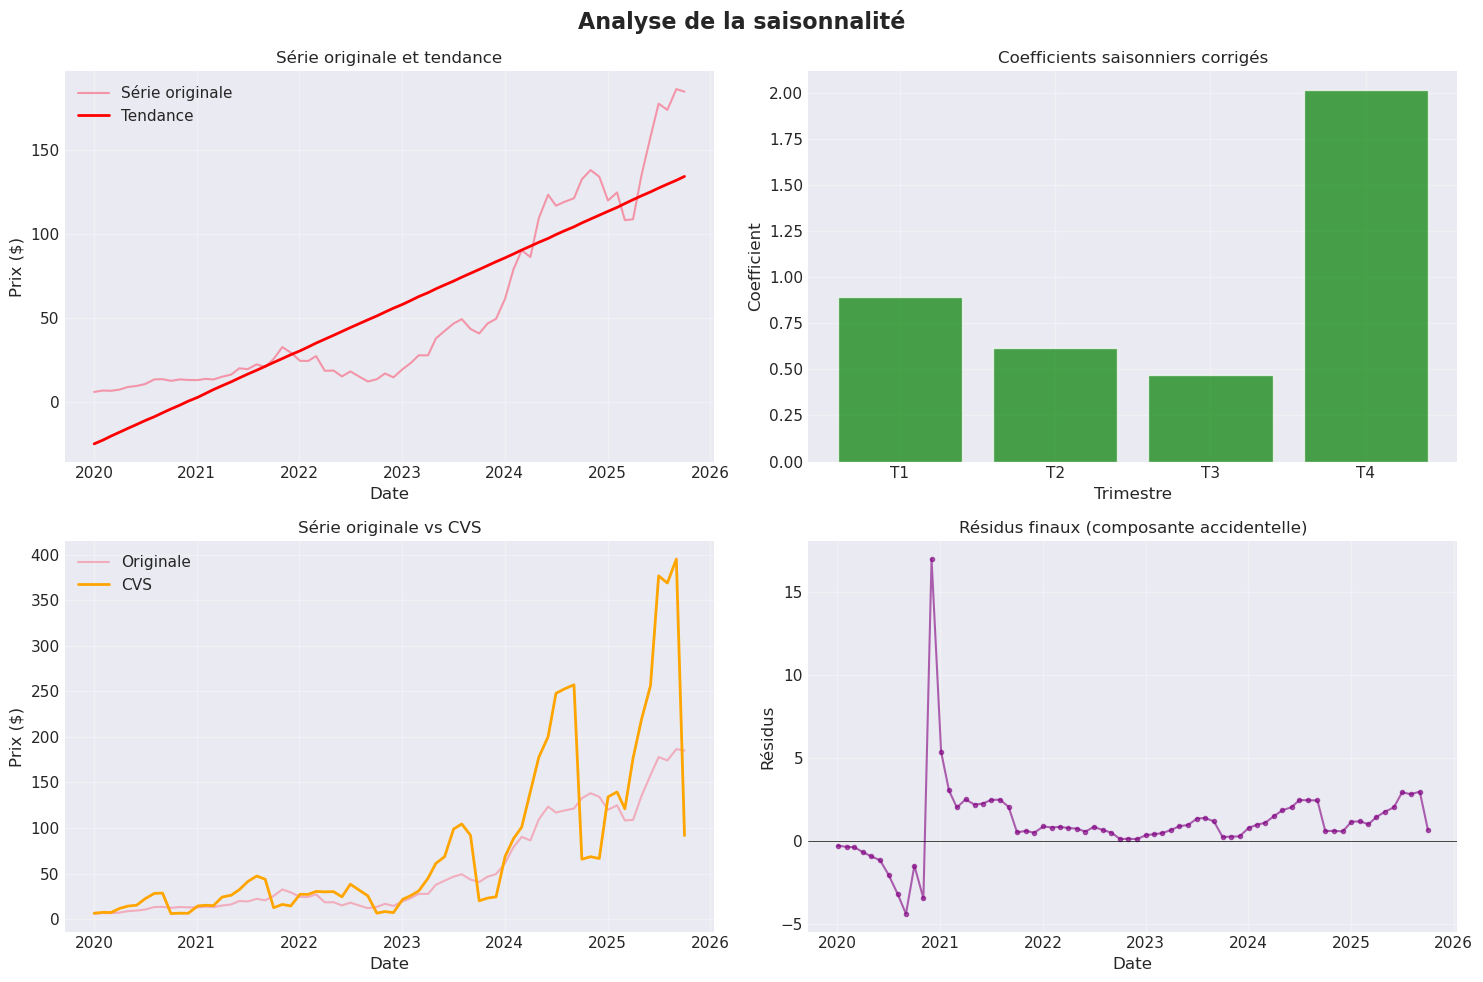


✅ Coefficients saisonniers déterminés



In [ ]:
# 4.1 Calcul de la tendance par régression linéaire
t = np.arange(1, len(df) + 1).reshape(-1, 1)
y = df['Close'].values

reg_tendance = LinearRegression()
reg_tendance.fit(t, y)
tendance = reg_tendance.predict(t)
a_trend = reg_tendance.coef_[0]
b_trend = reg_tendance.intercept_

print(f"\n📈 Équation de tendance: ŷ_t = {a_trend:.4f} × t + {b_trend:.4f}")

# 4.2 Calcul des résidus selon le modèle choisi
if modele_choisi == 'additif':
    residus = y - tendance
    print("→ Modèle additif: s_t = y_t - f_t")
else:
    residus = y / tendance
    print("→ Modèle multiplicatif: s_t = y_t / f_t")

# 4.3 Ajout des résidus au DataFrame
df['Tendance'] = tendance
df['Residu'] = residus

# 4.4 Calcul des coefficients saisonniers par trimestre
coeff_saisonniers = df.groupby('Quarter')['Residu'].mean().to_dict()

print("\n📊 Coefficients saisonniers bruts:")
for trimestre, coeff in coeff_saisonniers.items():
    print(f"  {trimestre}: {coeff:.4f}")

# 4.5 Vérification et correction
if modele_choisi == 'additif':
    # Pour additif: somme des coefficients doit être nulle
    moyenne_coeff = np.mean(list(coeff_saisonniers.values()))
    coeff_corriges = {k: v - moyenne_coeff for k, v in coeff_saisonniers.items()}
    print(f"\n🔄 Correction additive (moyenne = {moyenne_coeff:.4f})")
else:
    # Pour multiplicatif: moyenne des coefficients doit être 1
    moyenne_coeff = np.mean(list(coeff_saisonniers.values()))
    coeff_corriges = {k: v / moyenne_coeff for k, v in coeff_saisonniers.items()}
    print(f"\n🔄 Correction multiplicative (moyenne = {moyenne_coeff:.4f})")

print("\n✅ Coefficients saisonniers corrigés:")
for trimestre, coeff in coeff_corriges.items():
    print(f"  {trimestre}: {coeff:.4f}")

# Vérification
if modele_choisi == 'additif':
    somme = sum(coeff_corriges.values())
    print(f"\n🔍 Vérification: Somme des coefficients = {somme:.4f} ≈ 0")
else:
    moyenne = np.mean(list(coeff_corriges.values()))
    print(f"\n🔍 Vérification: Moyenne des coefficients = {moyenne:.4f} ≈ 1")

# 4.5 Calcul de la série CVS (Corrigée des Variations Saisonnières)
df['Coeff_Saisonnier'] = df['Quarter'].map(coeff_corriges)

if modele_choisi == 'additif':
    df['CVS'] = df['Close'] - df['Coeff_Saisonnier']
else:
    df['CVS'] = df['Close'] / df['Coeff_Saisonnier']

# 4.6 Analyse des résidus
if modele_choisi == 'additif':
    df['Residu_Final'] = df['Close'] - (df['Tendance'] + df['Coeff_Saisonnier'])
else:
    df['Residu_Final'] = df['Close'] / (df['Tendance'] * df['Coeff_Saisonnier'])

# 4.7 Visualisation des résultats
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Analyse de la saisonnalité', fontsize=16, fontweight='bold')

# Graphique 1: Série originale vs Tendance
axes[0,0].plot(df['Time'], df['Close'], label='Série originale', alpha=0.7)
axes[0,0].plot(df['Time'], df['Tendance'], label='Tendance', color='red', linewidth=2)
axes[0,0].set_title('Série originale et tendance')
axes[0,0].set_xlabel('Date')
axes[0,0].set_ylabel('Prix ($)')
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)

# Graphique 2: Coefficients saisonniers
trimestres = list(coeff_corriges.keys())
valeurs = list(coeff_corriges.values())
couleurs = ['green' if v > 0 else 'red' for v in valeurs]
axes[0,1].bar(trimestres, valeurs, color=couleurs, alpha=0.7)
axes[0,1].axhline(y=0, color='black', linestyle='-', linewidth=0.5)
axes[0,1].set_title('Coefficients saisonniers corrigés')
axes[0,1].set_xlabel('Trimestre')
axes[0,1].set_ylabel('Coefficient')
axes[0,1].grid(True, alpha=0.3)

# Graphique 3: Série CVS vs Originale
axes[1,0].plot(df['Time'], df['Close'], label='Originale', alpha=0.5)
axes[1,0].plot(df['Time'], df['CVS'], label='CVS', color='orange', linewidth=2)
axes[1,0].set_title('Série originale vs CVS')
axes[1,0].set_xlabel('Date')
axes[1,0].set_ylabel('Prix ($)')
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3)

# Graphique 4: Résidus finaux
axes[1,1].plot(df['Time'], df['Residu_Final'], color='purple', marker='.', linestyle='-', alpha=0.6)
axes[1,1].axhline(y=0, color='black', linestyle='-', linewidth=0.5)
axes[1,1].set_title('Résidus finaux (composante accidentelle)')
axes[1,1].set_xlabel('Date')
axes[1,1].set_ylabel('Résidus')
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n" + "="*80)
print("✅ Coefficients saisonniers déterminés")
print("="*80 + "\n")

## 🔮 5 - Prévision à l'aide du modèle retenu
### **Formules de prévision**

- **Modèle additif** : $\hat{y}_t = f_t + S'_j$
- **Modèle multiplicatif** : $\hat{y}_t = f_t \times S'_j$

où $j$ est le trimestre correspondant à la date $t$.


```python
# Code Python pour les prévisions


Dernier trimestre observé: T4
Trimestres futurs: ['T1', 'T2', 'T3', 'T4']

📈 Prévisions pour les 4 prochains trimestres:
Période Trimestre  Tendance  Coeff  Prévision
     T1        T1    136.79  0.895     122.40
     T2        T2    139.10  0.617      85.80
     T3        T3    141.41  0.472      66.78
     T4        T4    143.72  2.016     289.75


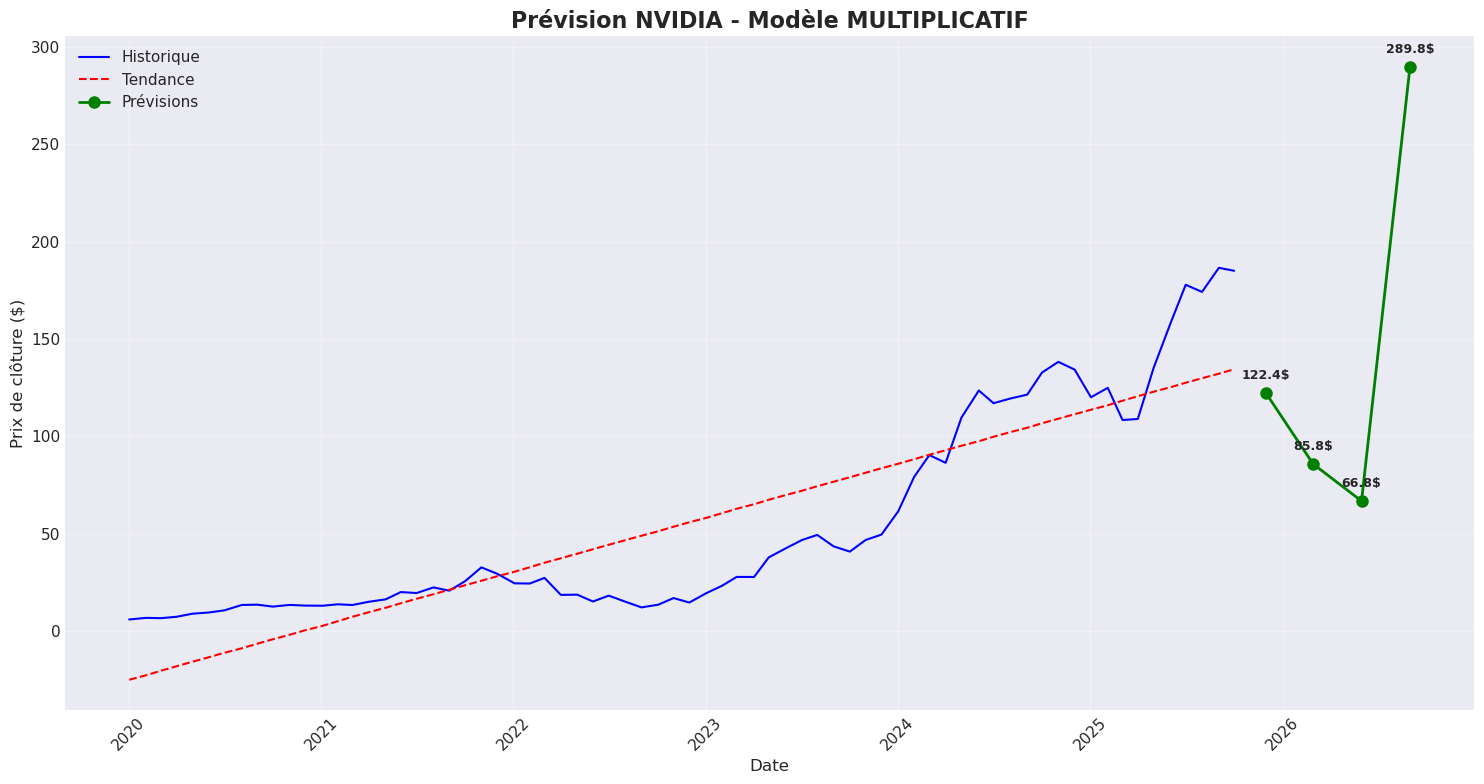

In [ ]:
# 5.1 Détermination des prochaines périodes
dernier_index = len(df)
prochaines_periodes = np.arange(dernier_index + 1, dernier_index + 5).reshape(-1, 1)

# 5.2 Calcul de la tendance future
tendance_future = reg_tendance.predict(prochaines_periodes)

# 5.3 Détermination des trimestres futurs (CORRIGÉ)
# Ordre normal: T1, T2, T3, T4
dernier_trimestre = df['Quarter'].iloc[-1]  # Dernier trimestre observé (T4)
trimestres_ordre = ['T1', 'T2', 'T3', 'T4']
index_depart = trimestres_ordre.index(dernier_trimestre) + 1

trimestres_futurs = []
for i in range(4):
    idx = (index_depart + i) % 4
    trimestres_futurs.append(trimestres_ordre[idx])

print(f"Dernier trimestre observé: {dernier_trimestre}")
print(f"Trimestres futurs: {trimestres_futurs}")

# 5.4 Calcul des prévisions
previsions = []
for i, (tendance, trimestre) in enumerate(zip(tendance_future.flatten(), trimestres_futurs)):
    coeff = coeff_corriges[trimestre]

    if modele_choisi == 'additif':
        prevision = tendance + coeff
    else:
        prevision = tendance * coeff

    previsions.append({
        'Période': f'T{i+1}',
        'Trimestre': trimestre,
        'Tendance': round(tendance, 2),
        'Coeff': round(coeff, 3),
        'Prévision': round(prevision, 2)
    })

# 5.5 Affichage des prévisions
df_previsions = pd.DataFrame(previsions)
print("\n📈 Prévisions pour les 4 prochains trimestres:")
print(df_previsions.to_string(index=False))

# 5.6 Visualisation des prévisions
plt.figure(figsize=(15, 8))

# Données historiques
plt.plot(df['Time'], df['Close'], label='Historique', color='blue', linewidth=1.5)

# Tendance
plt.plot(df['Time'], df['Tendance'], label='Tendance', color='red', linestyle='--', linewidth=1.5)

# Prévisions
dates_futures = pd.date_range(start=df['Time'].iloc[-1] + pd.DateOffset(months=1),
                             periods=4, freq='3ME')

plt.plot(dates_futures, [p['Prévision'] for p in previsions],
         'o-', color='green', linewidth=2, markersize=8, label='Prévisions')

# Ajouter les valeurs sur le graphique
for i, (date, prev) in enumerate(zip(dates_futures, previsions)):
    plt.annotate(f'{prev["Prévision"]:.1f}$',
                (date, prev['Prévision']),
                textcoords="offset points",
                xytext=(0,10),
                ha='center',
                fontsize=9,
                fontweight='bold')

plt.title(f'Prévision NVIDIA - Modèle {modele_choisi.upper()}', fontsize=16, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Prix de clôture ($)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 📈 PARTIE II: Méthode alternative de prévision
### **Lissage Exponentiel de Holt-Winters (Triple Exponential Smoothing)**

Cette méthode utilise **3 équations de lissage** :

- **Niveau (Level)** : $L_t = \alpha(Y_t - S_{t-p}) + (1-\alpha)(L_{t-1} + T_{t-1})$
- **Tendance (Trend)** : $T_t = \beta(L_t - L_{t-1}) + (1-\beta)T_{t-1}$
- **Saisonnalité (Seasonal)** : $S_t = \gamma(Y_t - L_t) + (1-\gamma)S_{t-p}$

**Prévision** : $\hat{Y}_{t+h} = L_t + h \times T_t + S_{t+h-p}$

### **Critères d'évaluation :**

- **MAE** (Mean Absolute Error) : $\frac{1}{n}\sum_{i=1}^n |y_i - \hat{y}_i|$
- **RMSE** (Root Mean Square Error) : $\sqrt{\frac{1}{n}\sum_{i=1}^n (y_i - \hat{y}_i)^2}$
- **MAPE** (Mean Absolute Percentage Error) : $\frac{100\%}{n}\sum_{i=1}^n \left|\frac{y_i - \hat{y}_i}{y_i}\right|$

```python
# Code Python pour Holt-Winters

📊 PARTIE II: MÉTHODE ALTERNATIVE DE PRÉVISION

📅 Période d'entraînement: 2020-01-02 à 2024-08-01
📅 Période de test: 2024-09-03 à 2025-10-01

📊 Performance du modèle Holt-Winters:
----------------------------------------
MAE  (Erreur Absolue Moyenne): 17.76 $
RMSE (Racine de l'Erreur Quadratique): 24.52 $
MAPE (Erreur Relative): 14.23 %


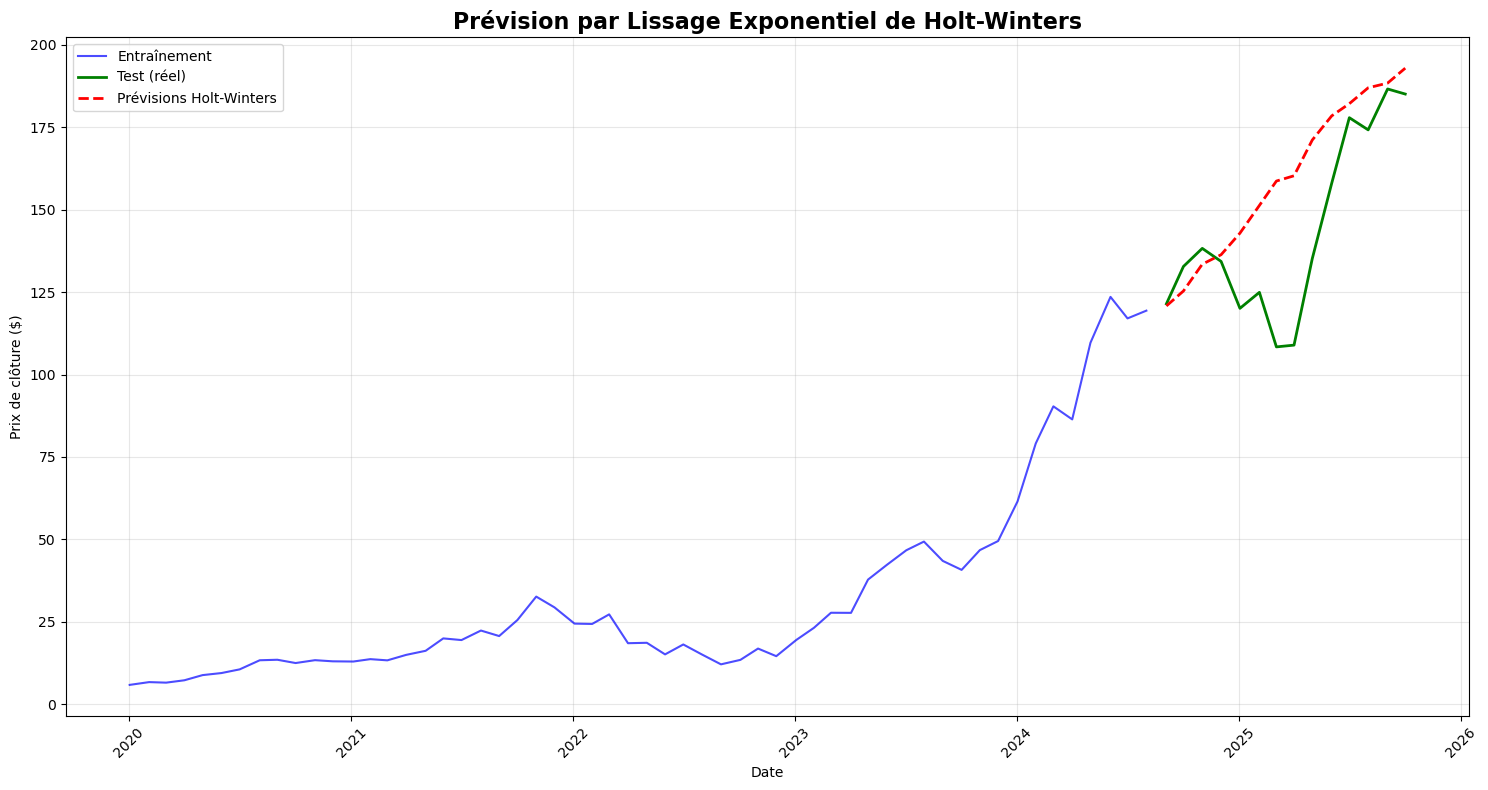


🔮 Prévisions Holt-Winters pour 2026:
----------------------------------------
2026-01: 120.80 $
2026-04: 136.33 $
2026-07: 158.66 $
2026-10: 178.42 $


In [ ]:

# Pour masquer les avertissements
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("="*80)
print("📊 PARTIE II: MÉTHODE ALTERNATIVE DE PRÉVISION")
print("="*80)

# 1. Préparation des données
df = pd.read_csv('Nvidia_Data.csv')
df['Time'] = pd.to_datetime(df['Time'])
df = df.sort_values('Time')
df.set_index('Time', inplace=True)

# 2. Séparation train/test (80% / 20%)
train_size = int(len(df) * 0.8)
train, test = df['Close'][:train_size], df['Close'][train_size:]

print(f"\n📅 Période d'entraînement: {train.index[0].date()} à {train.index[-1].date()}")
print(f"📅 Période de test: {test.index[0].date()} à {test.index[-1].date()}")

# 3. Modèle Holt-Winters
modele_hw = ExponentialSmoothing(
    train,
    seasonal_periods=12,
    trend='add',
    seasonal='add',
    initialization_method='estimated'
)

# 4. Entraînement
hw_fit = modele_hw.fit()

# 5. Prévisions sur la période de test
predictions = hw_fit.forecast(len(test))

# 6. Évaluation du modèle
mae = mean_absolute_error(test, predictions)
rmse = np.sqrt(mean_squared_error(test, predictions))
mape = np.mean(np.abs((test.values - predictions.values) / test.values)) * 100

print("\n📊 Performance du modèle Holt-Winters:")
print("-" * 40)
print(f"MAE  (Erreur Absolue Moyenne): {mae:.2f} $")
print(f"RMSE (Racine de l'Erreur Quadratique): {rmse:.2f} $")
print(f"MAPE (Erreur Relative): {mape:.2f} %")

# 7. Visualisation
plt.figure(figsize=(15, 8))

plt.plot(train.index, train, label='Entraînement', color='blue', alpha=0.7)
plt.plot(test.index, test, label='Test (réel)', color='green', linewidth=2)
plt.plot(test.index, predictions, label='Prévisions Holt-Winters',
         color='red', linestyle='--', linewidth=2)

plt.title('Prévision par Lissage Exponentiel de Holt-Winters', fontsize=16, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Prix de clôture ($)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 8. Prévision pour 2026 (4 trimestres) - avec freq='ME' au lieu de 'M'
previsions_2026 = hw_fit.forecast(12)

print("\n🔮 Prévisions Holt-Winters pour 2026:")
print("-" * 40)
dates_2026 = pd.date_range(start='2026-01-01', periods=12, freq='ME')  # 'ME' au lieu de 'M'
for i, (date, prev) in enumerate(zip(dates_2026, previsions_2026)):
    if i % 3 == 0:  # Afficher chaque trimestre
        print(f"{date.strftime('%Y-%m')}: {prev:.2f} $")